<h1><center>Практическое задание</h1></center>

1. Подобрать модель и с её помощью сделать паноптическую сегментацию на датасете VOCSegmentation

In [1]:
import torch
from transformers import AutoImageProcessor, DetrForSegmentation


model_name = 'facebook/detr-resnet-50-panoptic'
processor = AutoImageProcessor.from_pretrained(model_name)
model = DetrForSegmentation.from_pretrained(model_name)

params = sum(p.numel() for p in model.parameters())

Loading weights:   0%|          | 0/562 [00:00<?, ?it/s]

d:\MIREA\DPO\.venv3_11_8\Lib\site-packages\huggingface_hub\file_download.py:139: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\nuyki\.cache\huggingface\hub\models--facebook--detr-resnet-50-panoptic. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


In [7]:
model.cpu()

DetrForSegmentation(
  (detr): DetrForObjectDetection(
    (model): DetrModel(
      (backbone): DetrConvEncoder(
        (model): FeatureListNet(
          (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
          (bn1): DetrFrozenBatchNorm2d()
          (act1): ReLU(inplace=True)
          (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
          (layer1): Sequential(
            (0): Bottleneck(
              (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
              (bn1): DetrFrozenBatchNorm2d()
              (act1): ReLU(inplace=True)
              (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
              (bn2): DetrFrozenBatchNorm2d()
              (drop_block): Identity()
              (act2): ReLU(inplace=True)
              (aa): Identity()
              (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        

In [2]:
params

42899288

In [3]:
model_size = sum(p.numel() * p.element_size() for p in model.parameters()) / (1024 ** 2)
model_size

163.64779663085938

model.safetensors:   0%|          | 0.00/172M [00:00<?, ?B/s]

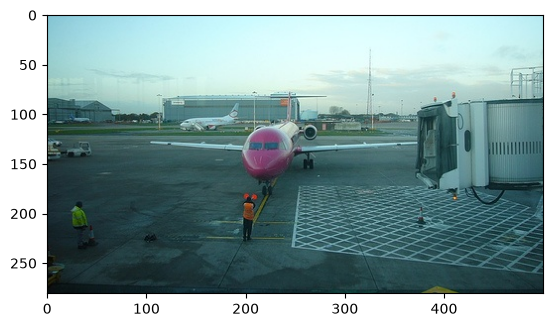

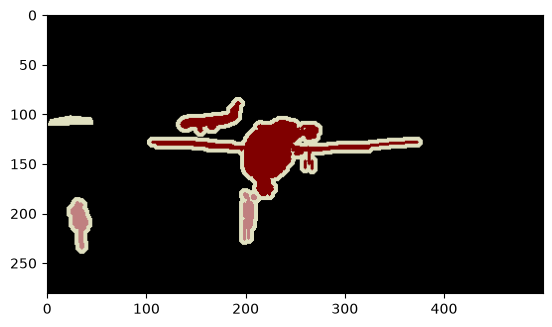

In [4]:
from torchvision.datasets import VOCSegmentation
from torchvision import transforms
import matplotlib.pyplot as plt
import numpy as np


dataset = VOCSegmentation(root='D:/MIREA/DPO/Learning/Practic2_8/SimpleNN', download=False, image_set='trainval')
plt.imshow(dataset[0][0])
plt.show()
plt.imshow(dataset[0][1])
plt.show()

In [16]:
random_index = np.random.choice(len(dataset), 1, replace=False)[0]
image = dataset[random_index][0]
target_size = [[image.height, image.width]]
input = processor(images=image, return_tensors="pt")
with torch.no_grad():
    output = model(**input)

print("Pred masks: ", output.pred_masks.shape)
print("Pred logits: ", output.logits.shape)

panoptic_results = processor.post_process_panoptic_segmentation(output, target_sizes=target_size)
panoptic_results

Pred masks:  torch.Size([1, 100, 200, 267])
Pred logits:  torch.Size([1, 100, 251])


[{'segmentation': tensor([[0, 0, 0,  ..., 0, 0, 0],
          [0, 0, 0,  ..., 0, 0, 0],
          [0, 0, 0,  ..., 0, 0, 0],
          ...,
          [2, 2, 2,  ..., 0, 0, 0],
          [2, 2, 2,  ..., 0, 0, 0],
          [2, 2, 2,  ..., 0, 0, 0]], dtype=torch.int32),
  'segments_info': [{'id': 1,
    'label_id': 193,
    'was_fused': False,
    'score': 0.968143},
   {'id': 2, 'label_id': 194, 'was_fused': False, 'score': 0.78498},
   {'id': 3, 'label_id': 18, 'was_fused': False, 'score': 0.570525},
   {'id': 4, 'label_id': 1, 'was_fused': False, 'score': 0.995303},
   {'id': 5, 'label_id': 44, 'was_fused': False, 'score': 0.95755}]}]

In [24]:
labels = {int(k): v for k, v in model.config.id2label.items()}
labels = dict(sorted(labels.items()))
print(labels)
COLORS = np.random.uniform(0, 255, size=(len(labels), 3))
COLORS

{0: 'N/A', 1: 'person', 2: 'bicycle', 3: 'car', 4: 'motorcycle', 5: 'airplane', 6: 'bus', 7: 'train', 8: 'truck', 9: 'boat', 10: 'traffic light', 11: 'fire hydrant', 12: 'street sign', 13: 'stop sign', 14: 'parking meter', 15: 'bench', 16: 'bird', 17: 'cat', 18: 'dog', 19: 'horse', 20: 'sheep', 21: 'cow', 22: 'elephant', 23: 'bear', 24: 'zebra', 25: 'giraffe', 26: 'hat', 27: 'backpack', 28: 'umbrella', 29: 'shoe', 30: 'eye glasses', 31: 'handbag', 32: 'tie', 33: 'suitcase', 34: 'frisbee', 35: 'skis', 36: 'snowboard', 37: 'sports ball', 38: 'kite', 39: 'baseball bat', 40: 'baseball glove', 41: 'skateboard', 42: 'surfboard', 43: 'tennis racket', 44: 'bottle', 45: 'plate', 46: 'wine glass', 47: 'cup', 48: 'fork', 49: 'knife', 50: 'spoon', 51: 'bowl', 52: 'banana', 53: 'apple', 54: 'sandwich', 55: 'orange', 56: 'broccoli', 57: 'carrot', 58: 'hot dog', 59: 'pizza', 60: 'donut', 61: 'cake', 62: 'chair', 63: 'couch', 64: 'potted plant', 65: 'bed', 66: 'mirror', 67: 'dining table', 68: 'window

array([[184.74111554,  31.14791044, 183.76548042],
       [132.83518533, 122.33876418, 159.40571401],
       [  5.26229822,  32.07708266, 241.25910696],
       [  6.77273057,  91.36635529,  88.64671469],
       [133.78636776,  63.01259481, 113.4832467 ],
       [191.34285953, 120.24827116,   5.27419944],
       [106.70285273,  44.0353875 , 107.35208101],
       [102.48956183,  97.66449533,  91.08783114],
       [ 24.3481125 , 193.35462883, 119.43208066],
       [ 52.92783734,  54.85882534,  52.97719837],
       [215.91361417, 145.16261057, 116.45264959],
       [ 45.33327753, 239.12918916,  80.66267939],
       [ 80.13810571, 197.3677388 , 108.03997419],
       [238.73282819, 124.66292916,  55.17703348],
       [ 34.79178487,  66.53045666,  42.1811348 ],
       [ 77.25912918, 245.48936   , 196.70624524],
       [ 75.4170189 , 183.09822585, 139.86246642],
       [158.32062253, 191.8755411 ,  82.98968634],
       [119.27349435, 139.17065295, 168.1251434 ],
       [189.12025915, 129.27632

In [ ]:
import cv2
from scipy.ndimage import center_of_mass


def pan_image(image, processor):
    target_size = [[image.height, image.width]]
    input = processor(images=image, return_tensors="pt")
    with torch.no_grad():
        output = model(**input)

    panoptic_results = processor.post_process_panoptic_segmentation(output, target_sizes=target_size)[0]
    return panoptic_results

def make_PS(dataset, number_images, processor, alpha=1, beta=.6):
    fig, axes = plt.subplots(number_images, 1, figsize=(15, number_images * 10))
    if number_images == 1:
        axes = np.expand_dims(axes, axis=0)

    random_indexes = np.random.choice(len(dataset), (5), replace=False)
    images = [dataset[i][0] for i in random_indexes]

    for idx, image in enumerate(images):
        ax = axes[idx]
        panoptic_results = pan_image(image, processor)
        seg_map = panoptic_results["segmentation"].cpu().numpy()
        seg_info = panoptic_results["segments_info"]
        final_image = image.copy()
        colored_mask = COLORS[seg_map].astype(np.uint8)
        image = np.array(image, dtype=np.uint8)
        blended_image = (image * alpha + colored_mask * beta).astype(np.uint8)
        ax.imshow(blended_image)
        
        for segment in seg_info:
            seg_id, seg_label, seg_fused, seg_score = segment.values()

            object_name = labels[seg_label]
            object_mask = (seg_map == seg_id)

            ax.contour(object_mask, colors="white", linewidths=0.5, levels=[0.5])
            center_x, center_y = center_of_mass(object_mask)

            if (not np.isnan(center_x) and not np.isnan(center_y)):
                ax.text(center_x, center_y, object_name, color="#C800FF", fontsize=8,
                        weight="bold")
            ax.axis("off")
    plt.show()

AttributeError: 'numpy.ndarray' object has no attribute 'axis'

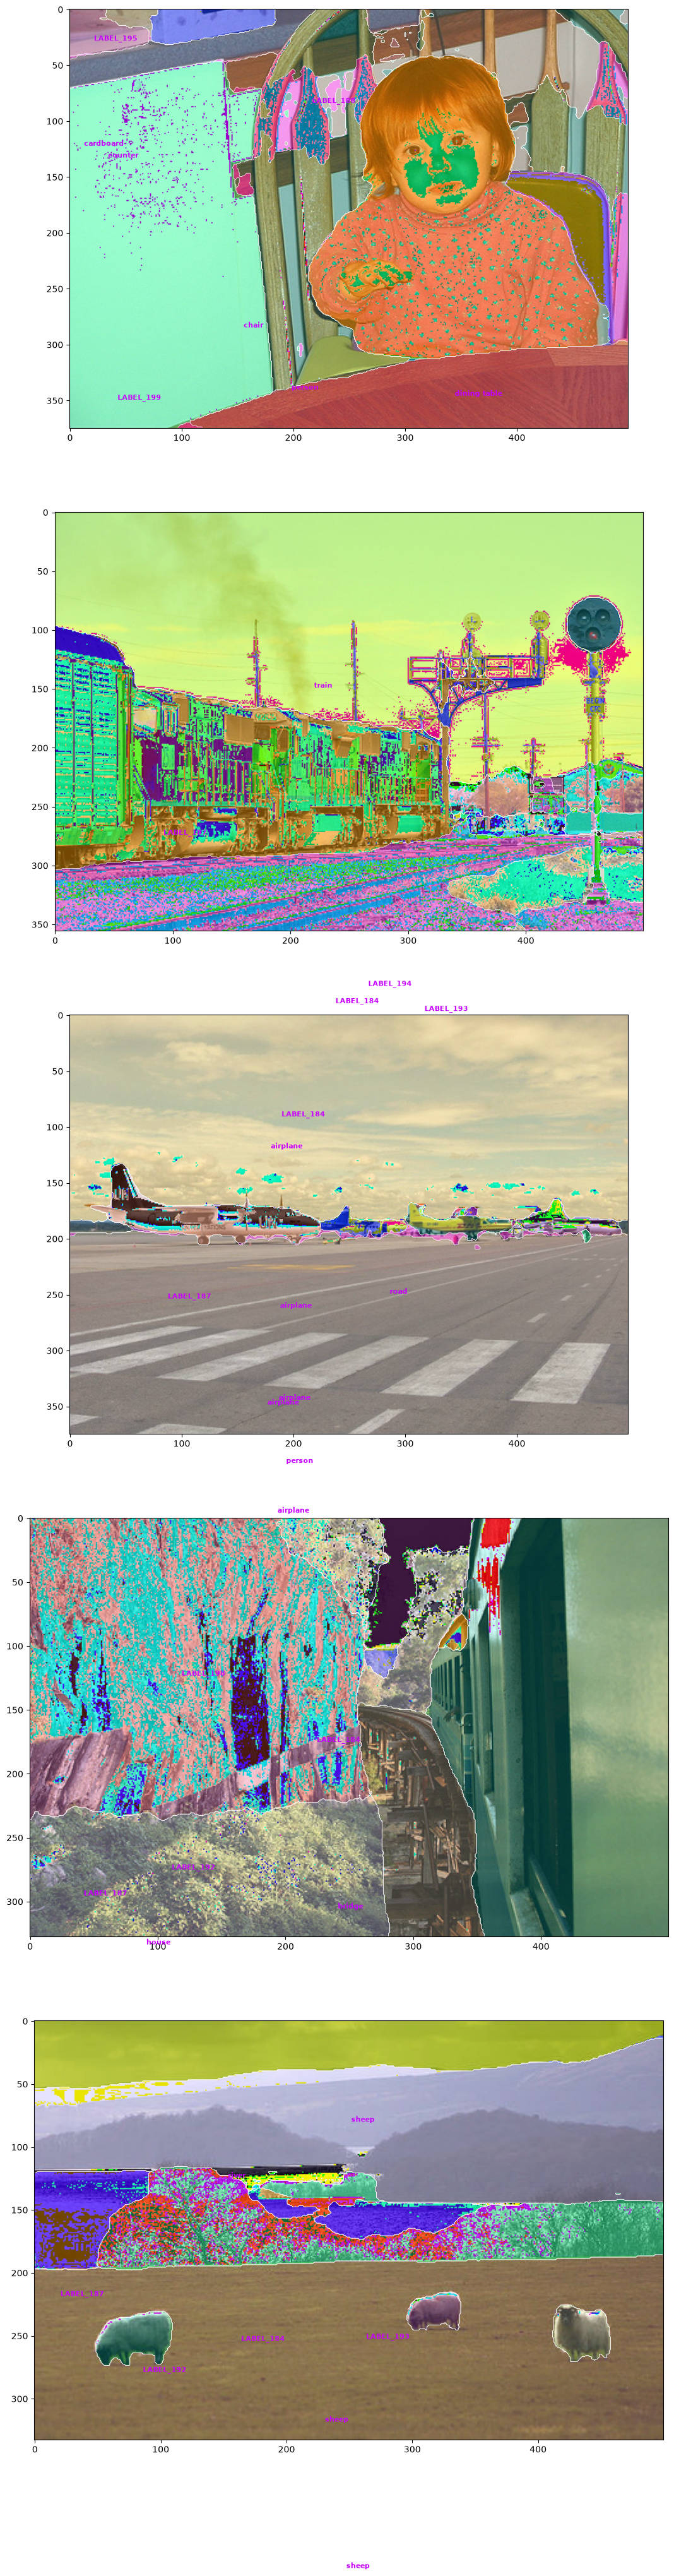

In [50]:
make_PS(dataset, 5, processor)

In [32]:
np.random.choice(len(dataset), (5), replace=False)

array([2732, 1547, 1817, 1597, 2016])